       COCO TRAFFIC DATASET EXPLORATION

PLEASE UPLOAD YOUR COCO128 ZIP FILE


Saving coco128.zip to coco128.zip

Dataset extracted successfully!
Total photographs: 128
Total annotation files: 128

TRAFFIC IMAGES FOUND: 22

REAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES


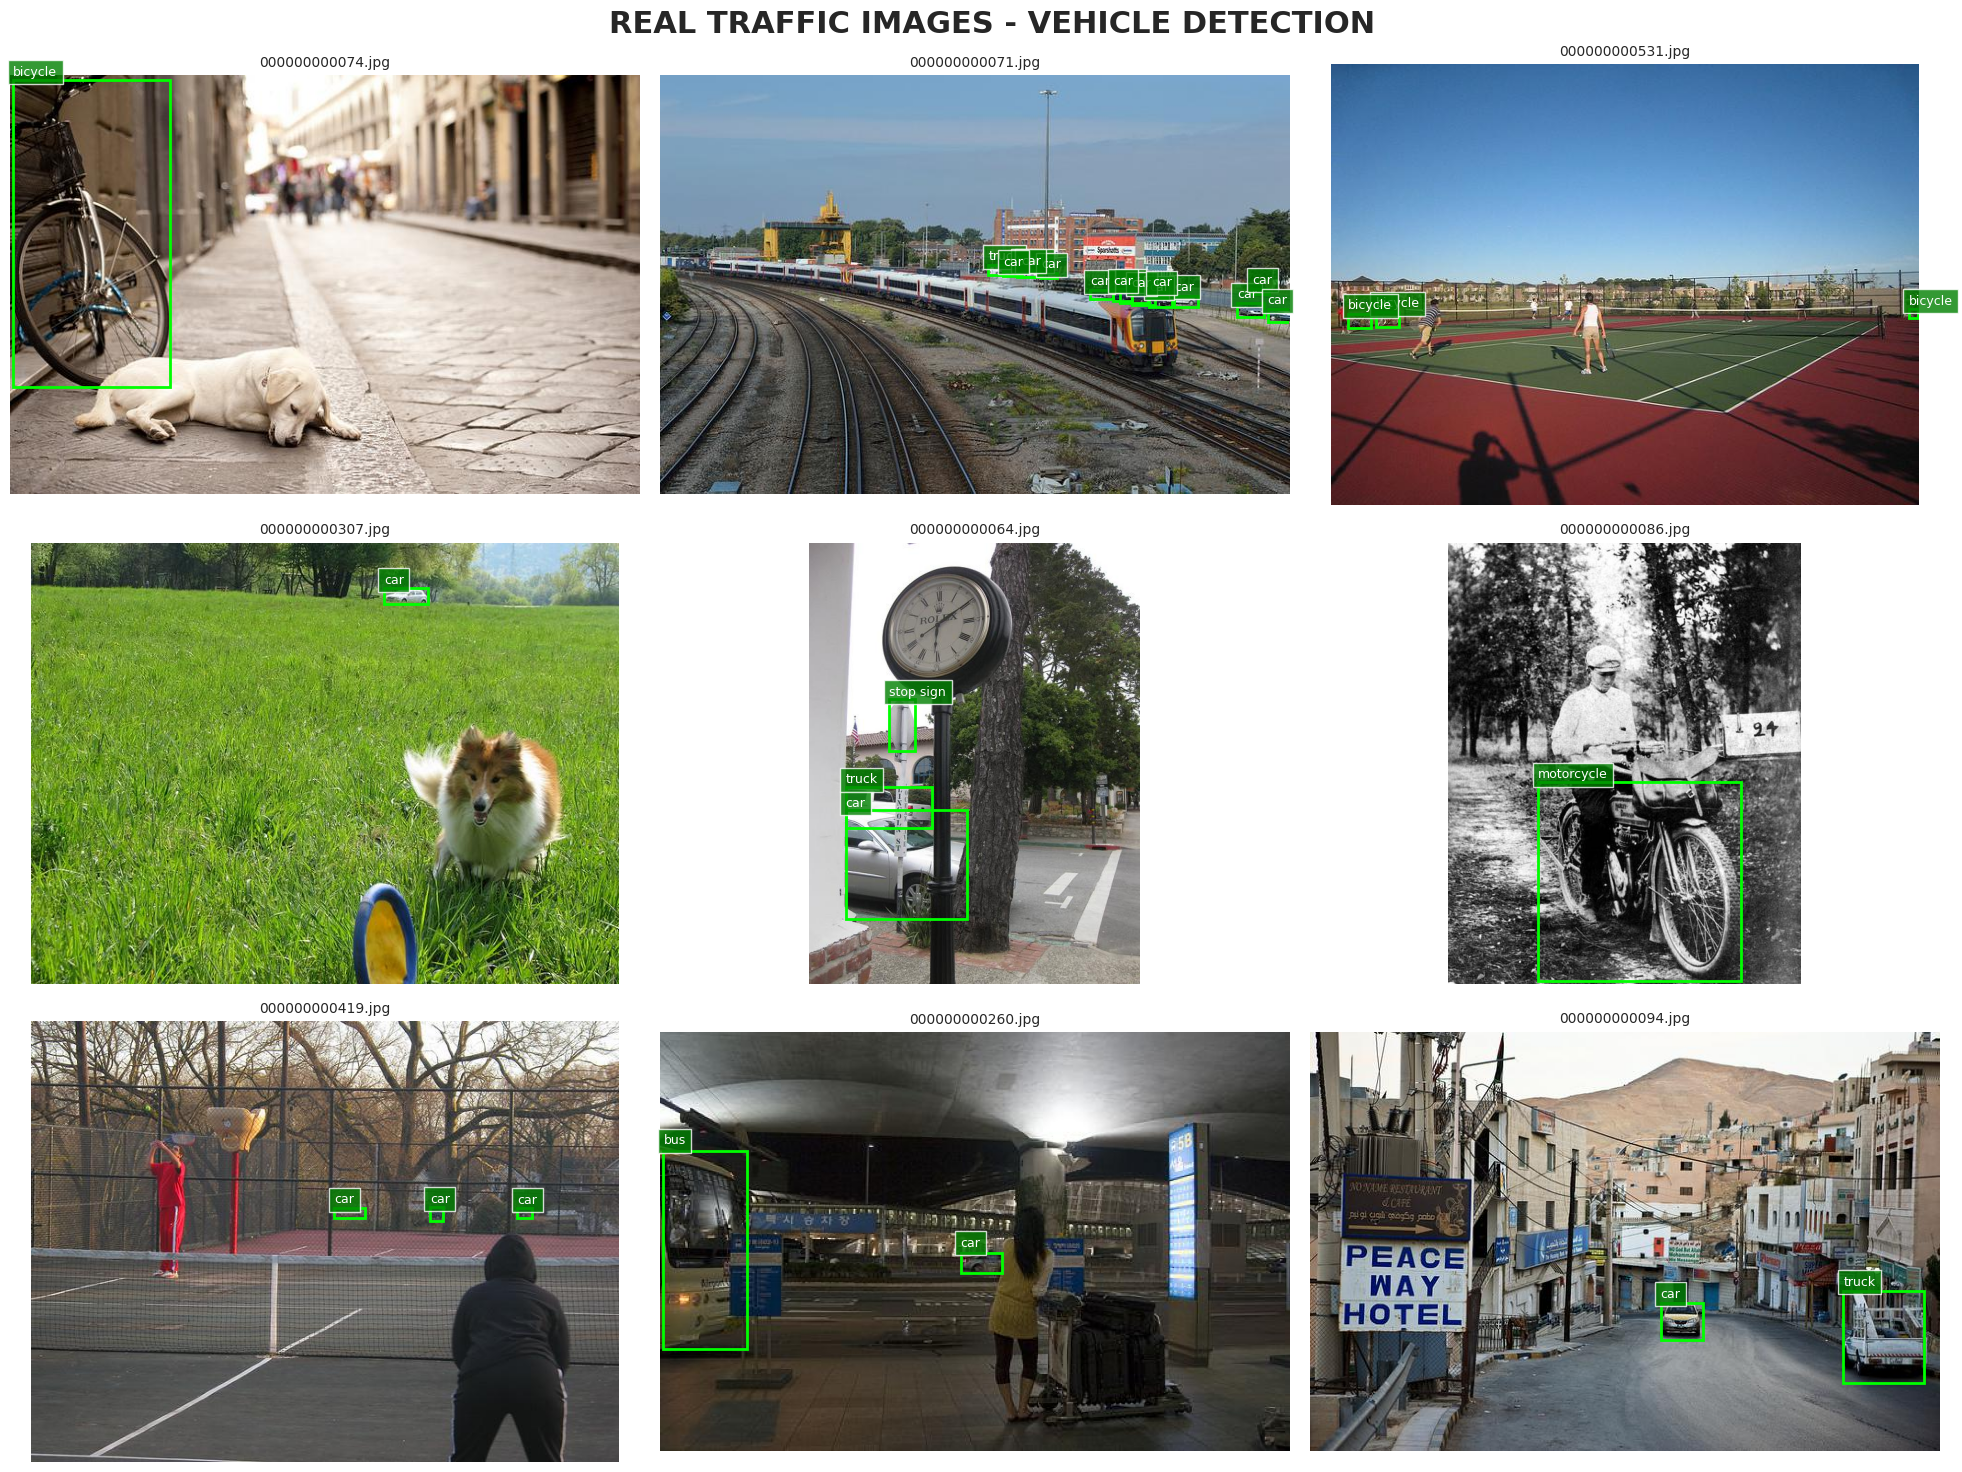

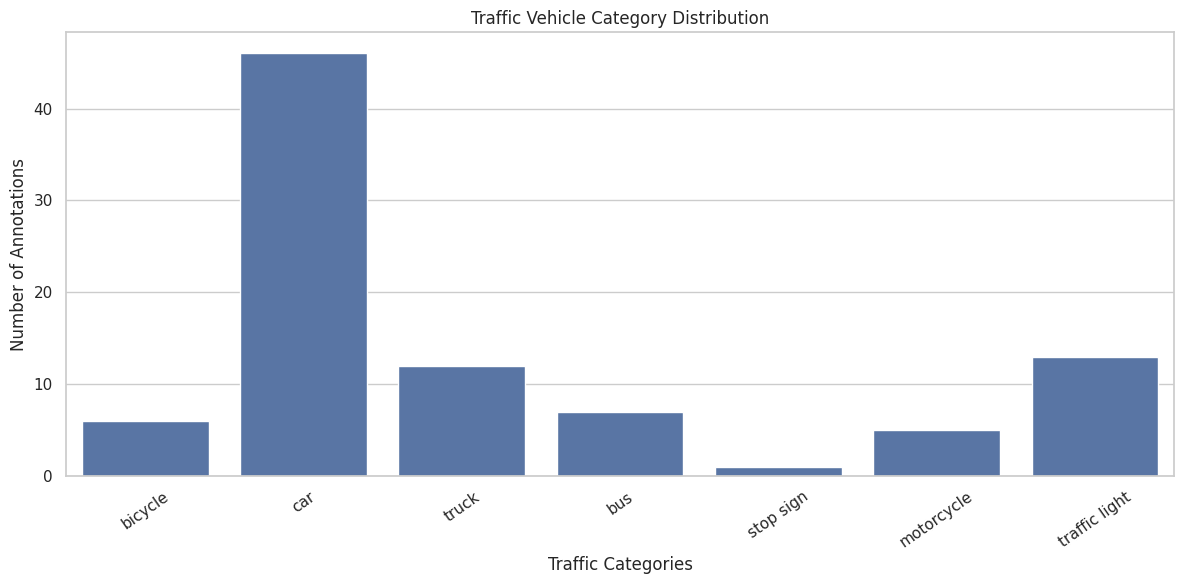

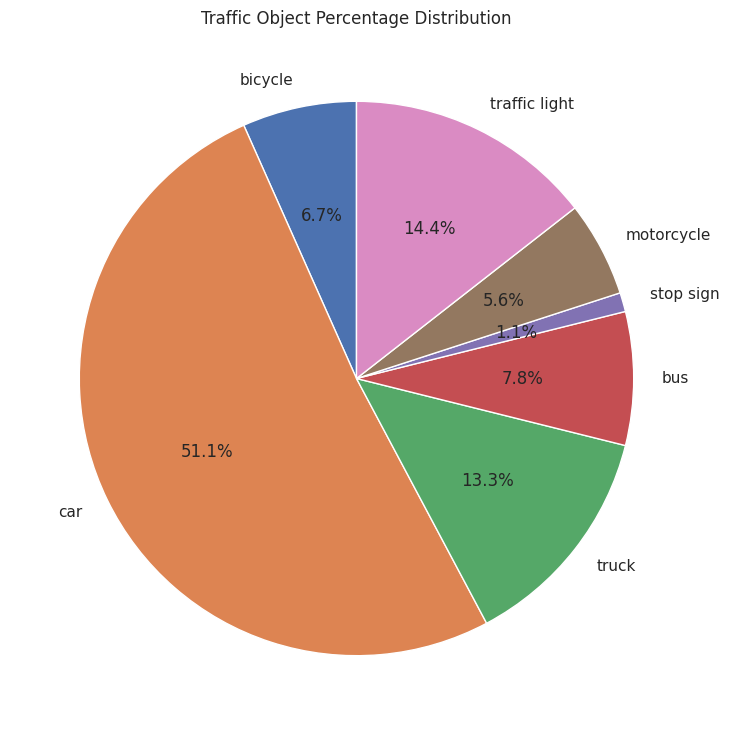

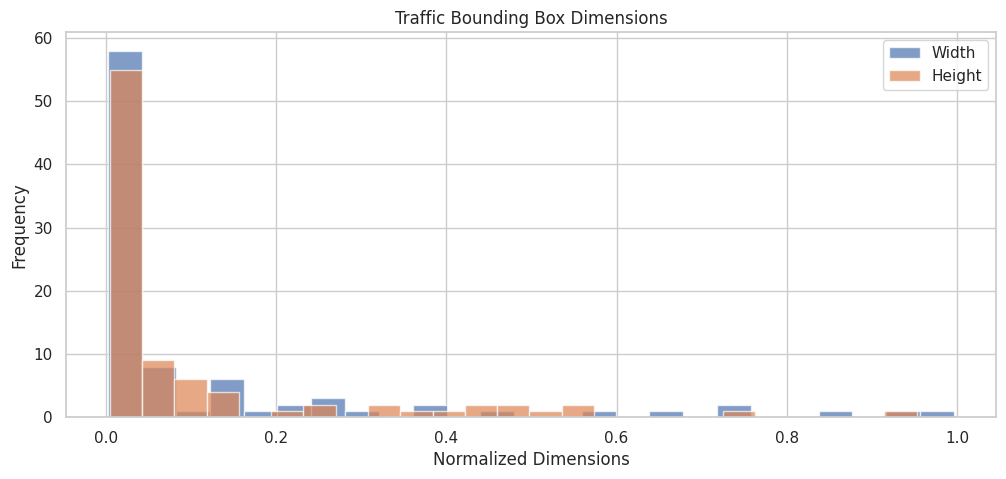

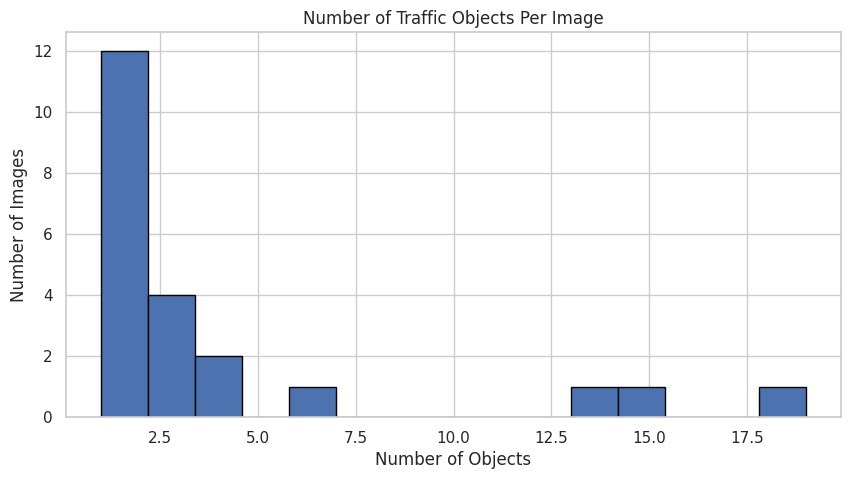


ANNOTATION TABLE


,Image,Category,X Center,Y Center,Width,Height
0,000000000531.jpg,bicycle,0.0961,0.5775,0.0396,0.0351
1,000000000531.jpg,bicycle,0.0487,0.5811,0.0394,0.0324
2,000000000531.jpg,bicycle,0.9905,0.5644,0.0164,0.0199
3,000000000094.jpg,car,0.5901,0.6896,0.0670,0.0901
4,000000000094.jpg,truck,0.9114,0.7254,0.1291,0.2190
5,000000000471.jpg,bus,0.5480,0.5112,0.7182,0.4966
6,000000000071.jpg,car,0.7526,0.5258,0.0434,0.0332
7,000000000071.jpg,car,0.8357,0.5385,0.0380,0.0282
8,000000000071.jpg,car,0.7009,0.5215,0.0364,0.0202
9,000000000071.jpg,car,0.9374,0.5598,0.0424,0.0336



       FINAL TRAFFIC DATASET REPORT
Total Dataset Images : 128
Traffic Images       : 22
Traffic Categories   : 7
Total Annotations    : 90

CATEGORY COUNTS
bicycle : 6
car : 46
truck : 12
bus : 7
stop sign : 1
motorcycle : 5
traffic light : 13

Average Objects Per Image: 4.09
Average Box Width: 0.1239
Average Box Height: 0.1124

EXPERIMENT COMPLETED SUCCESSFULLY!


In [2]:

# ================================================================
# DEEP LEARNING SKILL LAB
# COCO DATASET EXPLORATION - TRAFFIC IMAGE PROCESSING
# REAL PHOTOGRAPHS + BOUNDING BOX ANNOTATIONS
# ================================================================

!pip install -q numpy pandas matplotlib seaborn pillow

import os
import glob
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

from PIL import Image
from collections import Counter
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
random.seed(42)

print("=" * 65)
print("       COCO TRAFFIC DATASET EXPLORATION")
print("=" * 65)

# 1. UPLOAD COCO ZIP FILE
print("\nPLEASE UPLOAD YOUR COCO128 ZIP FILE")

uploaded = files.upload()

zip_file = next(
    (f for f in uploaded if f.lower().endswith(".zip")),
    None
)

if zip_file is None:
    raise ValueError("Please upload the COCO ZIP file!")

# 2. EXTRACT DATASET
dataset_path = "/content/traffic_coco"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall(dataset_path)

print("\nDataset extracted successfully!")

# 3. FIND IMAGE AND LABEL FOLDERS
image_files = glob.glob(
    dataset_path + "/**/images/**/*.jpg",
    recursive=True
)

if not image_files:
    image_files = glob.glob(
        dataset_path + "/**/*.jpg",
        recursive=True
    )

label_files = glob.glob(
    dataset_path + "/**/labels/**/*.txt",
    recursive=True
)

if not image_files:
    raise FileNotFoundError("No images found in ZIP!")

if not label_files:
    raise FileNotFoundError("No YOLO annotation files found!")

label_lookup = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in label_files
}

print("Total photographs:", len(image_files))
print("Total annotation files:", len(label_files))

# 4. COCO CATEGORY NAMES
class_names = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv",
    "laptop", "mouse", "remote", "keyboard", "cell phone",
    "microwave", "oven", "toaster", "sink", "refrigerator",
    "book", "clock", "vase", "scissors", "teddy bear",
    "hair drier", "toothbrush"
]

# 5. SELECT TRAFFIC OBJECTS
# Exclude person-only images.
# Main vehicle classes:
vehicle_ids = [1, 2, 3, 5, 7]

# Additional road-related objects:
road_ids = [9, 11, 12]

# Require at least one actual vehicle.
traffic_records = []
category_counts = Counter()

for image_path in image_files:

    name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    label_path = label_lookup.get(name)

    if not label_path:
        continue

    objects = []

    with open(label_path, "r") as f:
        lines = f.readlines()

    for line in lines:

        values = list(map(float, line.split()))

        if len(values) < 5:
            continue

        cid = int(values[0])

        if cid not in vehicle_ids + road_ids:
            continue

        xc, yc, w, h = values[1:5]

        obj = {
            "id": cid,
            "name": class_names[cid],
            "xc": xc,
            "yc": yc,
            "w": w,
            "h": h
        }

        objects.append(obj)

    # Only keep images containing a vehicle.
    has_vehicle = any(
        obj["id"] in vehicle_ids for obj in objects
    )

    if has_vehicle:

        traffic_records.append({
            "path": image_path,
            "objects": objects
        })

        for obj in objects:
            category_counts[obj["name"]] += 1

print("\nTRAFFIC IMAGES FOUND:", len(traffic_records))

if not traffic_records:
    raise ValueError(
        "No vehicle images found in this dataset. "
        "Please check that you uploaded COCO128."
    )

# 6. DISPLAY REAL TRAFFIC PHOTOGRAPHS
print("\nREAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES")

sample = random.sample(
    traffic_records,
    min(9, len(traffic_records))
)

fig, axes = plt.subplots(3, 3, figsize=(20, 15))
axes = axes.flatten()

for ax, record in zip(axes, sample):

    img = Image.open(record["path"]).convert("RGB")

    width, height = img.size

    ax.imshow(img)

    for obj in record["objects"]:

        # Normalized YOLO coordinates to pixels
        xc = obj["xc"] * width
        yc = obj["yc"] * height
        bw = obj["w"] * width
        bh = obj["h"] * height

        x = xc - bw / 2
        y = yc - bh / 2

        rectangle = patches.Rectangle(
            (x, y),
            bw,
            bh,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        ax.text(
            x,
            max(0, y - 5),
            obj["name"],
            color="white",
            fontsize=9,
            bbox=dict(
                facecolor="green",
                alpha=0.8
            )
        )

    ax.set_title(
        os.path.basename(record["path"]),
        fontsize=10
    )

    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.suptitle(
    "REAL TRAFFIC IMAGES - VEHICLE DETECTION",
    fontsize=22,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# 7. CATEGORY DISTRIBUTION
names = list(category_counts.keys())
counts = list(category_counts.values())

plt.figure(figsize=(12, 6))

sns.barplot(
    x=names,
    y=counts
)

plt.title("Traffic Vehicle Category Distribution")
plt.xlabel("Traffic Categories")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 8. CATEGORY PIE CHART
plt.figure(figsize=(9, 9))

plt.pie(
    counts,
    labels=names,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Traffic Object Percentage Distribution")
plt.show()

# 9. BOUNDING BOX ANALYSIS
widths = [
    obj["w"]
    for record in traffic_records
    for obj in record["objects"]
]

heights = [
    obj["h"]
    for record in traffic_records
    for obj in record["objects"]
]

plt.figure(figsize=(12, 5))

plt.hist(widths, bins=25, alpha=0.7, label="Width")
plt.hist(heights, bins=25, alpha=0.7, label="Height")

plt.title("Traffic Bounding Box Dimensions")
plt.xlabel("Normalized Dimensions")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# 10. OBJECTS PER IMAGE
objects_per_image = [
    len(record["objects"])
    for record in traffic_records
]

plt.figure(figsize=(10, 5))

plt.hist(objects_per_image, bins=15, edgecolor="black")

plt.title("Number of Traffic Objects Per Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")

plt.show()

# 11. ANNOTATION TABLE
rows = []

for record in traffic_records:

    for obj in record["objects"]:

        rows.append({
            "Image": os.path.basename(record["path"]),
            "Category": obj["name"],
            "X Center": round(obj["xc"], 4),
            "Y Center": round(obj["yc"], 4),
            "Width": round(obj["w"], 4),
            "Height": round(obj["h"], 4)
        })

df = pd.DataFrame(rows)

print("\nANNOTATION TABLE")
display(df.head(20))

# 12. FINAL REPORT
print("\n" + "=" * 60)
print("       FINAL TRAFFIC DATASET REPORT")
print("=" * 60)

print("Total Dataset Images :", len(image_files))
print("Traffic Images       :", len(traffic_records))
print("Traffic Categories   :", len(names))
print("Total Annotations    :", len(df))

print("\nCATEGORY COUNTS")

for name, count in category_counts.items():
    print(name, ":", count)

print("\nAverage Objects Per Image:",
      round(np.mean(objects_per_image), 2))

print("Average Box Width:",
      round(np.mean(widths), 4))

print("Average Box Height:",
      round(np.mean(heights), 4))

print("\nEXPERIMENT COMPLETED SUCCESSFULLY!")
print("=" * 60)
